In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import jmat

Sx, Sy, Sz = jmat(1, 'x'), jmat(1, 'y'), jmat(1, 'z')

D = 2870.0      # zero-field splitting, MHz
gam = 2.8025    # electron gyromagnetic ratio, MHz/G
print("setup ok")

setup ok


In [2]:
def H_nv(Bx=0.0, By=0.0, Bz=0.0):
    """NV electron spin-1 Hamiltonian in MHz. Fields in gauss, z is the NV axis."""
    return D * Sz**2 + gam * (Bx*Sx + By*Sy + Bz*Sz)

In [3]:
B = 50.0
E = H_nv(Bz=B).eigenenergies()
f_minus = E[1] - E[0]
f_plus = E[2] - E[0]

print("simulated:", f_minus, f_plus)
print("analytic: ", D - gam*B, D + gam*B)

simulated: 2729.875 3010.125
analytic:  2729.875 3010.125


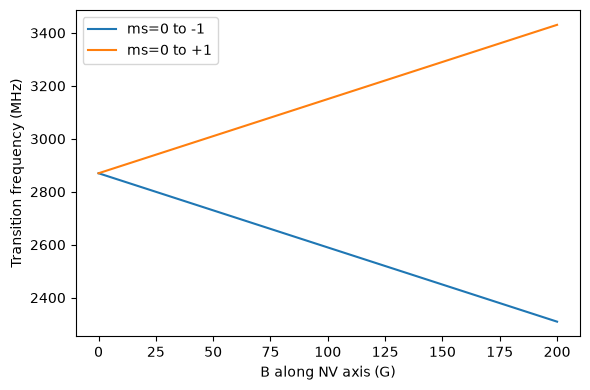

In [4]:
Bs = np.linspace(0, 200, 201)
f_lo, f_hi = [], []
for b in Bs:
    E = H_nv(Bz=b).eigenenergies()
    f_lo.append(E[1] - E[0])
    f_hi.append(E[2] - E[0])

plt.figure(figsize=(6, 4))
plt.plot(Bs, f_lo, label="ms=0 to -1")
plt.plot(Bs, f_hi, label="ms=0 to +1")
plt.xlabel("B along NV axis (G)")
plt.ylabel("Transition frequency (MHz)")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/fig1_resonance_vs_field.png", dpi=200)
plt.show()

In [5]:
B = 50.0
for theta_deg in [0, 15, 30, 60, 90]:
    th = np.deg2rad(theta_deg)
    E = H_nv(Bx=B*np.sin(th), Bz=B*np.cos(th)).eigenenergies()
    print(theta_deg, "deg: splitting =", round(E[2] - E[1], 2), "MHz")
    

0 deg: splitting = 280.25 MHz
15 deg: splitting = 270.68 MHz
30 deg: splitting = 242.64 MHz
60 deg: splitting = 140.09 MHz
90 deg: splitting = 6.83 MHz


In [6]:
from qutip import tensor, qeye

A_par = -2.14   # 14N hyperfine, MHz
P = -4.95       # 14N quadrupole, MHz
B = 50.0

Iz = jmat(1, 'z')
Sz_e = tensor(Sz, qeye(3))
Iz_n = tensor(qeye(3), Iz)

H = D*Sz_e**2 + gam*B*Sz_e + P*Iz_n**2 + A_par*Sz_e*Iz_n
Ediag = np.real(H.full().diagonal())

# basis order is +1, 0, -1 for both spins, index = 3*ms_index + mI_index
for j, mI in enumerate([1, 0, -1]):
    E_ms0 = Ediag[3*1 + j]
    E_msm1 = Ediag[3*2 + j]
    print("mI =", mI, ": ms=0 to -1 at", round(E_msm1 - E_ms0, 3), "MHz")

mI = 1 : ms=0 to -1 at 2732.015 MHz
mI = 0 : ms=0 to -1 at 2729.875 MHz
mI = -1 : ms=0 to -1 at 2727.735 MHz


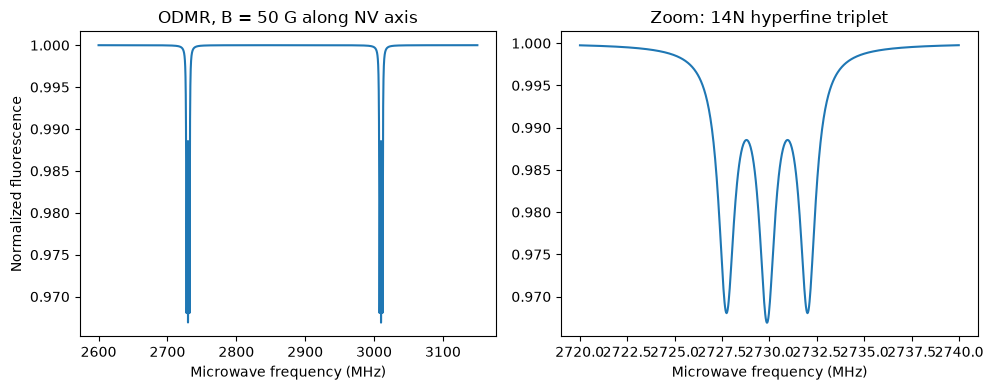

In [7]:
def odmr_lines(B):
    """All ms=0 to ms=+-1 transition frequencies (MHz) for on-axis field B (G)."""
    H = D*Sz_e**2 + gam*B*Sz_e + P*Iz_n**2 + A_par*Sz_e*Iz_n
    Ed = np.real(H.full().diagonal())   # H is diagonal for on-axis field
    lines = []
    for j in range(3):
        E0 = Ed[3*1 + j]                # ms = 0
        lines.append(Ed[3*0 + j] - E0)  # ms = +1
        lines.append(Ed[3*2 + j] - E0)  # ms = -1
    return np.array(lines)

def lorentz_dip(f, f0, fwhm, contrast):
    hw = fwhm / 2
    return contrast * hw**2 / ((f - f0)**2 + hw**2)

B = 50.0
fwhm, contrast = 1.0, 0.03   # MHz, fractional fluorescence dip

f = np.linspace(2600, 3150, 20000)
signal = np.ones_like(f)
for f0 in odmr_lines(B):
    signal -= lorentz_dip(f, f0, fwhm, contrast)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(f, signal)
ax[0].set_xlabel("Microwave frequency (MHz)")
ax[0].set_ylabel("Normalized fluorescence")
ax[0].set_title("ODMR, B = 50 G along NV axis")

m = (f > 2720) & (f < 2740)
ax[1].plot(f[m], signal[m])
ax[1].set_xlabel("Microwave frequency (MHz)")
ax[1].set_title("Zoom: 14N hyperfine triplet")

plt.tight_layout()
plt.savefig("../figures/fig2_odmr_spectrum.png", dpi=200)
plt.show()